In [2]:
!pip install MetaTrader5 pandas numpy scikit-learn matplotlib seaborn
!pip install ta 
!pip install python-dotenv 

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
  Using cached ta-0.11.0.tar.gz (25 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for ta: filename=ta-0.11.0-py3-none-any.whl size=29432 sha256=f7925df6655dc2cfdf2e8ad01e6dd3a2a63e139b9b78f071de4d55447c097619
  Stored in directory: c:\users\moi\appdata\local\pip\cache\wheels\ec\b6\81\d781ff040ee9432384560f29596ee14ca79d70529d4228e50f
Successfully built ta



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!python -c "import MetaTrader5 as mt5; print(mt5.__version__)"

5.0.6231


In [6]:
# TITLE: Analyse & Préparation des Données - Prédire le prix des 5 prochains jours MetaTrader 5 EURUSD avec Python

# Chapitre 1 : Introduction MetaTrader 5 & Installation des dépendances

import MetaTrader5 as mt5
import pandas as pd
from datetime import datetime, timedelta

if not mt5.initialize():
    print("Erreur de connexion")
    quit()

# Afficher les infos du compte
account_info = mt5.account_info()
print(f"Compte: {account_info.name}")
print(f"Solde: {account_info.balance}")
print(f"Devise: {account_info.currency}")


Compte: Kennedy Ndjibu
Solde: 100000.0
Devise: USD


In [7]:
# Chapitre 2 : Extraction des données
# Télécharger les données EURUSD
symbol = "EURUSD"
timeframe = mt5.TIMEFRAME_D1  # Daily
start_date = datetime(2020, 1, 1)
end_date = datetime.now()

# Télécharger les ticks / taux historiques
rates = mt5.copy_rates_range(symbol, timeframe, start_date, end_date)

# Convertir en DataFrame
df = pd.DataFrame(rates)
df['time'] = pd.to_datetime(df['time'], unit='s')
df.set_index('time', inplace=True)

print(f"Shape: {df.shape}")
print(df.head())

Shape: (1765, 7)
               open     high      low    close  tick_volume  spread  \
time                                                                  
2020-01-02  1.12132  1.12143  1.11635  1.11722        30404       1   
2020-01-03  1.11722  1.11797  1.11250  1.11558        39449       1   
2020-01-06  1.11646  1.12054  1.11571  1.11968        32448       1   
2020-01-07  1.11960  1.11975  1.11335  1.11526        35909       1   
2020-01-08  1.11529  1.11681  1.11016  1.11053        50619       1   

            real_volume  
time                     
2020-01-02            0  
2020-01-03            0  
2020-01-06            0  
2020-01-07            0  
2020-01-08            0  


              open         high          low        close    tick_volume  \
count  1765.000000  1765.000000  1765.000000  1765.000000    1765.000000   
mean      1.117141     1.121220     1.113523     1.117288   81262.849292   
std       0.056224     0.055709     0.056600     0.056202   49622.750106   
min       0.959230     0.967110     0.953570     0.959240      18.000000   
25%       1.078700     1.082560     1.076010     1.078810   48682.000000   
50%       1.112950     1.117390     1.109230     1.113160   65017.000000   
75%       1.165380     1.169010     1.162490     1.165660   98414.000000   
max       1.232560     1.234940     1.226570     1.232520  327221.000000   

            spread  real_volume  
count  1765.000000       1765.0  
mean      0.561473          0.0  
std       3.163047          0.0  
min       0.000000          0.0  
25%       0.000000          0.0  
50%       0.000000          0.0  
75%       0.000000          0.0  
max     112.000000          0.0  

Pertes (

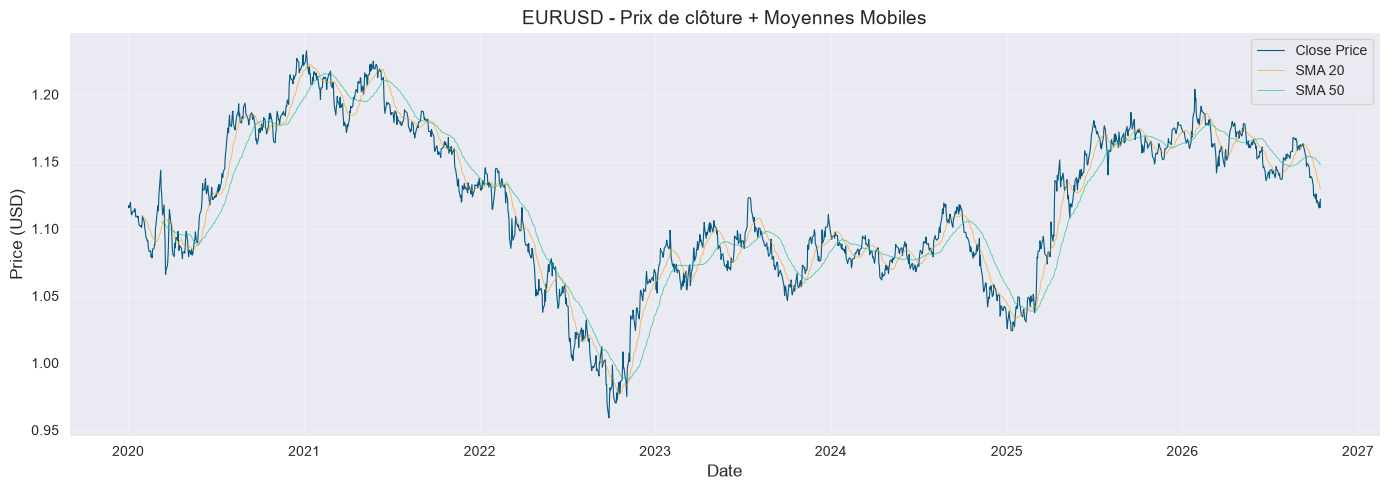

Volatilité quotidienne: 0.4615%
Range moyen: 0.6948%


In [8]:
# Chapitre 3 : Analyse Exploratoire (EDA) & Visualisation

# Statistiques Descriptives
print(df.describe())
print(f"\nPertes (NaN): {df.isnull().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")

# Stats temporelles
print(f"Période: {df.index.min()} à {df.index.max()}")
print(f"Nombre de jours: {len(df)}")
print(f"Écart entre données: {df.index[1] - df.index[0]}")


# Visualisation : Prix de clôture + Moyennes Mobiles
import matplotlib.pyplot as plt
import seaborn as sns

# Style élégant
sns.set_style("darkgrid")
plt.figure(figsize=(14, 5))

# Calcul préalable des SMA pour le graphique (si non fait)
df['sma_20'] = df['close'].rolling(20).mean()
df['sma_50'] = df['close'].rolling(50).mean()

# Tracer close price
plt.plot(df.index, df['close'], linewidth=0.8, color='#065A82', label='Close Price')
# Ajouter moyennes mobiles
plt.plot(df.index, df['sma_20'], linewidth=0.6, color='#F59E0B', alpha=0.7, label='SMA 20')
plt.plot(df.index, df['sma_50'], linewidth=0.6, color='#10B981', alpha=0.7, label='SMA 50')

plt.title('EURUSD - Prix de clôture + Moyennes Mobiles', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Volatilité & Variations
# Rendements (returns)
df['returns'] = df['close'].pct_change() * 100

# Volatilité (écart-type des rendements)
volatility = df['returns'].std()
print(f"Volatilité quotidienne: {volatility:.4f}%")

# High-Low range (variation intra-période)
df['hl_range'] = ((df['high'] - df['low']) / df['close']) * 100
print(f"Range moyen: {df['hl_range'].mean():.4f}%")

In [9]:
# Chapitre 4 : Nettoyage des données (NaN, Anomalies, Doublons)
# Gérer les valeurs manquantes (NaN)
missing = df.isnull().sum()
print(f"Valeurs manquantes:\n{missing}")

# Option 1 : Supprimer (attention au volume)
df_clean = df.dropna()
# Option 2 : Interpoler linéairement
df_interp = df.interpolate(method='linear')
# Option 3 : Backward fill (utiliser dernière valeur)
df_bfill = df.bfill()


# Détection et traitement des anomalies (Méthode IQR)
import numpy as np

Q1 = df['returns'].quantile(0.25)
Q3 = df['returns'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['returns'] < lower) | (df['returns'] > upper)]
print(f"Outliers trouvés: {len(outliers)}")


# Gestion des doublons
print(f"Index doublés: {df.index.duplicated().sum()}")
print(f"Lignes doublées: {df.duplicated().sum()}")
df_dedup = df[~df.duplicated(keep='first')]

Valeurs manquantes:
open            0
high            0
low             0
close           0
tick_volume     0
spread          0
real_volume     0
sma_20         19
sma_50         49
returns         1
hl_range        0
dtype: int64
Outliers trouvés: 57
Index doublés: 0
Lignes doublées: 0


In [11]:
# Chapitre 5 : Feature Engineering
# Features Temporelles
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['dayofweek'] = df.index.dayofweek  # 0=Monday, 6=Sunday
df['hour'] = df.index.hour

# Indicateurs cycliques / booléens
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_month_start'] = df.index.is_month_start.astype(int)
df['is_month_end'] = df.index.is_month_end.astype(int)


# Returns & Momentum
df['ret_1d'] = df['close'].pct_change() * 100
df['ret_5d'] = df['close'].pct_change(5) * 100
df['log_ret'] = np.log(df['close'] / df['close'].shift(1)) * 100
df['momentum_5'] = df['close'].diff(5)
df['momentum_10'] = df['close'].diff(10)
df['roc_5'] = ((df['close'] - df['close'].shift(5)) / df['close'].shift(5)) * 100


# Volatilité & Range
df['volatility_20'] = df['close'].pct_change().rolling(20).std() * 100
df['volatility_50'] = df['close'].pct_change().rolling(50).std() * 100
df['hl_range'] = ((df['high'] - df['low']) / df['close']) * 100
df['close_pos'] = ((df['close'] - df['low']) / (df['high'] - df['low']))
# Bollinger Bands
df['bb_middle'] = df['close'].rolling(20).mean()
df['bb_std'] = df['close'].rolling(20).std()
df['bb_upper'] = df['bb_middle'] + (2 * df['bb_std'])
df['bb_lower'] = df['bb_middle'] - (2 * df['bb_std'])

In [12]:
# Moyennes Mobiles & Tendances
df['sma_20'] = df['close'].rolling(20).mean()
df['sma_50'] = df['close'].rolling(50).mean()
df['sma_200'] = df['close'].rolling(200).mean()
df['ema_12'] = df['close'].ewm(span=12, adjust=False).mean()
df['ema_26'] = df['close'].ewm(span=26, adjust=False).mean()
df['signal_sma_cross'] = (df['sma_20'] > df['sma_50']).astype(int)


# RSI (Relative Strength Index)
def calc_rsi(prices, period=14):
    """Calcul du Relative Strength Index"""
    delta = prices.diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

df['rsi_14'] = calc_rsi(df['close'], period=14)
df['overbought'] = (df['rsi_14'] > 70).astype(int)
df['oversold'] = (df['rsi_14'] < 30).astype(int)


# MACD (Moving Average Convergence Divergence)
def calc_macd(prices, fast=12, slow=26, signal=9):
    """Calcul du MACD"""
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    
    macd = ema_fast - ema_slow
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    histogram = macd - signal_line
    
    return macd, signal_line, histogram

df['macd'], df['macd_signal'], df['macd_hist'] = calc_macd(df['close'])
df['macd_signal_cross'] = (df['macd'] > df['macd_signal']).astype(int)


# Nettoyage des NaN générés par les indicateurs techniques et rolling windows
df = df.dropna()

In [13]:
# Chapitre 6 : Normalisation & Scaling

# Simulation du Train/Test split pour l'exemple de scaling
train_size_temp = int(len(df) * 0.7)
X_train_demo = df.iloc[:train_size_temp]
X_val_demo = df.iloc[train_size_temp:]
X_test_demo = df.iloc[train_size_temp:]  # Exemple simplifié

# Option A : StandardScaler (Z-score)
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()
# FIT sur données d'entraînement uniquement (évite data leakage)
X_train_scaled = scaler.fit_transform(X_train_demo)
X_val_scaled = scaler.transform(X_val_demo)
X_test_scaled = scaler.transform(X_test_demo)

# Sauver le scaler pour données futures
joblib.dump(scaler, 'scaler.pkl')
print(f"Mean (StandardScaler): {scaler.mean_}")
print(f"Std (StandardScaler): {scaler.scale_}")


# Option B : MinMaxScaler (Normalisation [0,1])
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler(feature_range=(0, 1))
X_train_minmax = scaler_minmax.fit_transform(X_train_demo)
joblib.dump(scaler_minmax, 'scaler_minmax.pkl')
print(f"Min (MinMaxScaler): {scaler_minmax.data_min_}")


Mean (StandardScaler): [ 1.10532256e+00  1.10924835e+00  1.10164246e+00  1.10532809e+00
  7.76827810e+04  1.42335766e-01  0.00000000e+00  1.10642672e+00
  1.10809884e+00 -9.91271707e-03  6.95999133e-01  2.02235401e+03
  6.75821168e+00  1.57098540e+01  1.99908759e+00  0.00000000e+00
  0.00000000e+00  3.19343066e-02  3.19343066e-02 -9.91271707e-03
 -5.00260039e-02 -1.09882999e-02 -6.08503650e-04 -1.14471715e-03
 -5.00260039e-02  4.41501681e-01  4.43152980e-01  4.85071681e-01
  1.10642672e+00  8.16180513e-03  1.12275033e+00  1.09010311e+00
  1.11096799e+00  1.10597301e+00  1.10674094e+00  4.10583942e-01
  4.84740043e+01  9.94525547e-02  1.36861314e-01 -7.67928371e-04
 -7.51763119e-04 -1.61652522e-05  5.02737226e-01]
Std (StandardScaler): [6.06206426e-02 5.99698182e-02 6.10963600e-02 6.05846137e-02
 4.21758070e+04 8.60633159e-01 1.00000000e+00 6.00409706e-02
 5.94657294e-02 4.63725760e-01 3.44355726e-01 1.22572872e+00
 3.49333647e+00 8.75548491e+00 1.41259942e+00 1.00000000e+00
 1.00000000

In [16]:
# Chapitre 7 : Préparation pour le Machine Learning & Séquences Multi-Step

#Diviser Train / Validation / Test (Time-based split obligatoire)
train_size = int(len(df) * 0.7)  # 70% train
val_size = int(len(df) * 0.15)   # 15% val

X_train = df.iloc[:train_size]
X_val = df.iloc[train_size:train_size+val_size]
X_test = df.iloc[train_size+val_size:]

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")


#Préparation pour LSTM : Prédire 5 jours (Multi-Step)
def create_sequences_multiStep(data, seq_length=60, forecast_horizon=5):
    X, y = [], []
    for i in range(len(data) - seq_length - forecast_horizon):
        X.append(data[i:i+seq_length])  # 60 jours d'historique
        # Target : 5 prochains close prices (colonne index 3 = close)
        y.append(data[i+seq_length:i+seq_length+forecast_horizon, 3])
    return np.array(X), np.array(y)

seq_length = 60
forecast_horizon = 5  # 5 jours à prédire
X_train_seq, y_train_seq = create_sequences_multiStep(X_train.values, seq_length, forecast_horizon)
print(f"Shape X_train_seq: {X_train_seq.shape} | Shape y_train_seq: {y_train_seq.shape}")


#Préparation pour Linear Regression : 5 outputs
feature_cols = ['close', 'returns', 'momentum_5', 'volatility_20', 'sma_20', 'rsi_14']
X_train_lr = X_train[feature_cols].copy()

# Targets : 5 jours à l'avance
y_train_d1 = X_train_lr['close'].shift(-1)
y_train_d2 = X_train_lr['close'].shift(-2)
y_train_d3 = X_train_lr['close'].shift(-3)
y_train_d4 = X_train_lr['close'].shift(-4)
y_train_d5 = X_train_lr['close'].shift(-5)

# Empiler en array (samples, 5)
y_train_lr = np.column_stack([y_train_d1, y_train_d2, y_train_d3, y_train_d4, y_train_d5])

# Supprimer NaN de fin de shift
X_train_lr = X_train_lr[:-5]
y_train_lr = y_train_lr[:-5]

print(f"Shape X_train_lr: {X_train_lr.shape} | Shape y_train_lr: {y_train_lr.shape}")


Train: 1096 | Val: 234 | Test: 236
Shape X_train_seq: (1031, 60, 43) | Shape y_train_seq: (1031, 5)
Shape X_train_lr: (1091, 6) | Shape y_train_lr: (1091, 5)
